# 02. Mô tả và khám phá dữ liệu — Anh

Ánh xạ báo cáo: 2.1 nguồn và cấu trúc; 2.2 thách thức; 2.3 mô tả, trực quan và tương quan. Notebook chỉ đọc Parquet, không huấn luyện mô hình. Nếu thiếu thư viện: `%pip install pandas numpy scipy matplotlib plotly pyarrow`.

Phương pháp: McCracken & Ng (2016), doi:10.1080/07350015.2015.1086655; Spearman (1904), doi:10.2307/1412159; Wilson (1927), doi:10.1080/01621459.1927.10502953; Cramér (1946), Mathematical methods of statistics.

In [1]:

from pathlib import Path
import sys, json, hashlib, warnings
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# Trên Colab: mount Drive trước, rồi điền BASE là thư mục PTDLNC đã tải lên.
# Không cần sửa khi mở notebook từ bên trong thư mục dự án trên máy cá nhân.
BASE = next((p for p in [Path.cwd(), *Path.cwd().parents, Path.cwd() / 'PTDLNC']
             if (p / 'data' / 'raw').is_dir()), None)
if BASE is None:
    raise FileNotFoundError('Đặt BASE tới thư mục PTDLNC có data/raw (xem README).')
RANDOM_STATE = 42
RAW, PROCESSED, META = [BASE / 'data' / x for x in ('raw', 'processed', 'metadata')]
DATASET = json.loads((META / 'dataset_config.json').read_text(encoding='utf-8'))
SNAPSHOT = pd.Timestamp(DATASET['snapshot'])
SNAPSHOT_VI = DATASET['snapshot_vi']
WORK = BASE / 'bai_lam_Anh_Chuong2'
FIGURES, TABLES = WORK / 'figures', WORK / 'tables'
for p in (PROCESSED, META, FIGURES, TABLES): p.mkdir(parents=True, exist_ok=True)
def save_json(obj, path):
    path.write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
def sha256(path):
    h = hashlib.sha256()
    with path.open('rb') as f:
        for b in iter(lambda: f.read(1024*1024), b''): h.update(b)
    return h.hexdigest()
def table(frame, name):
    frame.to_csv(TABLES / (name + '.csv'), index=False, encoding='utf-8-sig', float_format='%.12g')
    display(frame.head(30))


## 1. Đọc dữ liệu và quy ước mẫu
Tất cả khoản vay dùng cho mô tả; PIF/CHGOFF dùng cho tỷ lệ xóa nợ. NAICS: giữ mã sáu chữ số, gộp các dải ngành 31–33, 44–45, 48–49; mã không hợp lệ để thiếu, không gán ngành tùy ý.

In [2]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Polygon, Patch
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from scipy.stats import chi2_contingency
import itertools
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,
                     'axes.spines.right':False,'figure.facecolor':'white','axes.titleweight':'bold'})
COLOR, ACCENT = '#164e63', '#c65d3b'
loans = pd.read_parquet(PROCESSED/'loans_clean.parquet')
fred = pd.read_parquet(PROCESSED/'fred_md_monthly.parquet')
assert loans.AsOfDate.eq(SNAPSHOT).all(), 'Parquet khác phiên bản đang dùng; chạy notebook 01 trước.'
audit=json.loads((META/'pipeline_audit.json').read_text(encoding='utf-8'))
assert audit.get('snapshot')==DATASET['snapshot'], 'Metadata pipeline lỗi thời.'
if all((RAW / item['file']).exists() for item in DATASET['sources']):
    assert audit.get('source_hashes') == {item['file']:sha256(RAW / item['file']) for item in DATASET['sources']}, 'CSV đã thay đổi; chạy lại notebook 01.'
assert not {'BorrName','BorrStreet','BorrCity','BorrZip','LocationID'}.intersection(loans.columns)
assert loans.is_resolved.eq(loans.target.notna()).all()
assert loans.fy.between(2000,2019).all()
raw_naics = loans.NaicsCode.str.replace(r'\.0$','',regex=True)
valid_naics = raw_naics.str.fullmatch(r'[1-9]\d{5}',na=False)
loans['NAICS2'] = raw_naics.where(valid_naics).str[:2].replace({'31':'31–33','32':'31–33','33':'31–33',
                  '44':'44–45','45':'44–45','48':'48–49','49':'48–49'})
SECTORS = {'11':'Nông, lâm, ngư nghiệp','21':'Khai khoáng','22':'Tiện ích','23':'Xây dựng',
 '31–33':'Chế biến, chế tạo','42':'Bán buôn','44–45':'Bán lẻ','48–49':'Vận tải, kho bãi',
 '51':'Thông tin','52':'Tài chính, bảo hiểm','53':'Bất động sản, cho thuê','54':'Chuyên môn, kỹ thuật',
 '55':'Quản lý doanh nghiệp','56':'Hỗ trợ, xử lý chất thải','61':'Giáo dục','62':'Y tế, trợ giúp xã hội',
 '71':'Nghệ thuật, giải trí','72':'Lưu trú, ăn uống','81':'Dịch vụ khác','92':'Hành chính công'}
loans['NAICS2'] = loans.NAICS2.where(loans.NAICS2.isin(SECTORS))
resolved = loans.loc[loans.is_resolved].copy()
SOURCE = f'Nguồn: tác giả tính toán từ SBA 7(a), bản chụp {SNAPSHOT_VI}.'
def savefig(fig, name, note=''):
    fig.text(0.01,0.012,SOURCE + ('\n'+note if note else ''),fontsize=8,va='bottom',color='#444444')
    fig.tight_layout(rect=(0,0.085,1,0.96))
    fig.savefig(FIGURES/(name+'.png'),dpi=200,bbox_inches='tight')
    plt.show()
    plt.close(fig)
def rate_table(group):
    allg=loans.groupby(group,dropna=False).agg(n_all=('fy','size'),mean_approval=('GrossApproval','mean'))
    r=resolved.groupby(group,dropna=False).agg(n_resolved=('target','size'),n_chgoff=('target','sum'))
    out=allg.join(r).reset_index()
    out[['n_resolved','n_chgoff']]=out[['n_resolved','n_chgoff']].fillna(0).astype(int)
    n=out.n_resolved.replace(0,np.nan); p=out.n_chgoff/n; z=1.959963984540054
    center=(p+z*z/(2*n))/(1+z*z/n)
    margin=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/(1+z*z/n)
    out['rate']=p;out['ci_low']=center-margin;out['ci_high']=center+margin
    out['low_n']=out.n_resolved.lt(100)
    return out


## 2. Bảng bằng chứng cho 2.2 và 2.3.1
Không bù thiếu hoặc loại ngoại lai. Mốc 300 tháng chỉ đánh dấu rà soát, không phải kết luận vi phạm pháp lý. JobsSupported = 0 được giữ; đây là số tự báo cáo trên hồ sơ, không phải kết quả việc làm đã kiểm chứng. Khoảng Wilson 95% chỉ có nghĩa mô tả trên khoản có nhãn, chưa điều chỉnh cụm.

In [3]:

numeric=['GrossApproval','SBAGuaranteedApproval','TermInMonths','JobsSupported','InitialInterestRate']
desc=loans[numeric].describe(percentiles=[.01,.25,.5,.75,.95,.99]).T.reset_index(names='variable')
desc['skewness']=loans[numeric].skew().reindex(desc.variable).to_numpy()
table(desc,'B3_mo_ta_dinh_luong')
missing=pd.DataFrame({'variable':loans.columns,'missing_n':loans.isna().sum().to_numpy(),
                      'missing_pct':loans.isna().mean().to_numpy()*100}).sort_values('missing_pct',ascending=False)
table(missing,'B4_thieu_du_lieu')
cats=[c for c in ['BusinessType','BusinessAge','Subprogram','ProcessingMethod','NAICS2','BorrState','LoanStatus'] if c in loans.columns]
freq=[]
for c in cats:
    a=loans[c].fillna('(Thiếu)').value_counts(dropna=False).rename_axis('category').reset_index(name='n')
    a.insert(0,'variable',c);a['pct_all']=a.n/len(loans)*100;freq.append(a)
table(pd.concat(freq,ignore_index=True),'B5_tan_so_dinh_tinh')
missing_fy=loans.groupby('fy')[numeric+['BusinessAge','NaicsCode','BorrState']].agg(lambda s:s.isna().mean()*100)
table(missing_fy.reset_index(),'B6_thieu_theo_fy')
outliers=[]
for c in ['GrossApproval','TermInMonths','JobsSupported']:
    s=loans[c].dropna();q1,q3=s.quantile([.25,.75]);iqr=q3-q1
    outliers.append(dict(variable=c,n_valid=len(s),q1=q1,q3=q3,iqr=iqr,
      lower_fence=q1-1.5*iqr,upper_fence=q3+1.5*iqr,
      outside_iqr_n=int(((s<q1-1.5*iqr)|(s>q3+1.5*iqr)).sum()),
      zero_n=int(s.eq(0).sum()),negative_n=int(s.lt(0).sum()),maximum=s.max()))
table(pd.DataFrame(outliers),'B7_ngoai_lai')
cohort=loans.groupby('fy').agg(n_all=('fy','size'),n_resolved=('is_resolved','sum'),n_chgoff=('target','sum'))
statuses=pd.crosstab(loans.fy,loans.LoanStatus)
cohort=cohort.join(statuses);cohort['resolved_rate']=cohort.n_resolved/cohort.n_all
cohort['chgoff_rate_resolved']=cohort.n_chgoff/cohort.n_resolved
cohort['exempt_share']=cohort.get('EXEMPT',0)/cohort.n_all
table(cohort.reset_index(),'B8_cohort')
for c in [c for c in ['BusinessType','Subprogram','ProcessingMethod','NAICS2','BorrState'] if c in loans.columns]:
    table(rate_table(c),'B9_ty_le_'+c)
classes=resolved.target.value_counts().sort_index()
summary={'n_all':len(loans),'n_resolved':len(resolved),'n_chgoff':int(classes.get(1,0)),
 'n_pif':int(classes.get(0,0)),'chgoff_rate':float(resolved.target.mean()),
 'n_status':{str(k):int(v) for k,v in loans.LoanStatus.value_counts(dropna=False).items()},
 'approval_start':str(loans.ApprovalDate.min().date()),'approval_end':str(loans.ApprovalDate.max().date()),
 'n_naics_missing_or_invalid':int(loans.NAICS2.isna().sum()),
 'negative_gross_n':int(loans.GrossApproval.lt(0).sum()),'term_gt_300_n':int(loans.TermInMonths.gt(300).sum()),
 'zero_term_n':int(loans.TermInMonths.eq(0).sum()),'zero_jobs_n':int(loans.JobsSupported.eq(0).sum()),
 'gross_total':float(loans.GrossApproval.sum()),'processed_columns':len(loans.columns)-1}
save_json(summary,META/'eda_summary.json')


,variable,count,mean,std,min,1%,25%,50%,75%,95%,99%,max,skewness
0,GrossApproval,1236084.0,266432.106183,508232.138467,55.00,5000.00,29700.0,89500.0,260000.00,1190000.00,2550000.00,5000000.0,4.415815
1,SBAGuaranteedApproval,1236084.0,195042.332044,388347.383914,46.75,2500.00,15000.0,50000.0,186000.00,900000.00,1932063.75,4500000.0,4.469483
2,TermInMonths,1236084.0,107.811192,75.280301,0.00,5.00,60.0,84.0,120.00,300.00,300.00,847.0,1.483828
3,JobsSupported,1236082.0,9.142202,24.339938,0.00,0.00,1.0,4.0,10.00,35.00,85.00,9500.0,97.811031
4,InitialInterestRate,582384.0,6.531841,1.545972,0.00,3.75,5.5,6.0,7.49,9.75,11.00,56.0,0.893748


,variable,missing_n,missing_pct
15,FranchiseCode,1148897,92.946515
20,ChargeOffDate,1057595,85.560124
26,SoldSecMrktInd,966624,78.200511
10,InitialInterestRate,653700,52.884755
11,FixedorVariableInterestInd,653699,52.884675
19,PaidInFullDate,381141,30.834555
31,target,202637,16.393465
8,FirstDisbursementDate,150607,12.184204
14,NaicsDescription,19780,1.600215
32,NAICS2,19779,1.600134


,variable,category,n,pct_all
0,BusinessType,CORPORATION,980591,79.33045
1,BusinessType,INDIVIDUAL,225468,18.240508
2,BusinessType,PARTNERSHIP,29475,2.384547
3,BusinessType,(Thiếu),550,0.044495
4,BusinessAge,Less than 4 years old but at least 3,367663,29.744176
5,BusinessAge,"Existing, 5 or more years",328882,26.606768
6,BusinessAge,"New, Less than 1 Year old",209378,16.938816
7,BusinessAge,"Startup, Loan Funds will Open Business",105441,8.530246
8,BusinessAge,Unanswered,74191,6.0021
9,BusinessAge,Existing or more than 2 years old,51896,4.19842


,fy,GrossApproval,SBAGuaranteedApproval,TermInMonths,JobsSupported,InitialInterestRate,BusinessAge,NaicsCode,BorrState
0,2000,0.0,0.0,0.0,0.000000,100.000000,0.006857,45.037487,0.0
1,2001,0.0,0.0,0.0,0.000000,100.000000,0.002328,0.169933,0.0
2,2002,0.0,0.0,0.0,0.000000,100.000000,0.0,0.0,0.0
3,2003,0.0,0.0,0.0,0.000000,100.000000,0.002972,0.0,0.0
4,2004,0.0,0.0,0.0,0.000000,100.000000,0.002465,0.0,0.0
5,2005,0.0,0.0,0.0,0.000000,100.000000,0.003128,0.0,0.0
6,2006,0.0,0.0,0.0,0.000000,100.000000,0.013362,0.0,0.0
7,2007,0.0,0.0,0.0,0.000000,100.000000,0.017067,0.0,0.0
8,2008,0.0,0.0,0.0,0.000000,100.000000,0.017282,0.0,0.0
9,2009,0.0,0.0,0.0,0.000000,11.274462,0.055706,0.002422,0.0


,variable,n_valid,q1,q3,iqr,lower_fence,upper_fence,outside_iqr_n,zero_n,negative_n,maximum
0,GrossApproval,1236084,29700.0,260000.0,230300.0,-315750.0,605450.0,142931,0,0,5000000.0
1,TermInMonths,1236084,60.0,120.0,60.0,-30.0,210.0,157778,1138,0,847.0
2,JobsSupported,1236082,1.0,10.0,9.0,-12.5,23.5,108562,223310,0,9500.0


,fy,n_all,n_resolved,n_chgoff,CANCLD,CHGOFF,COMMIT,EXEMPT,PIF,resolved_rate,chgoff_rate_resolved,exempt_share
0,2000,43748,37529,5557,6148,5557,0,71,31972,0.857845,0.148072,0.001623
1,2001,42958,37236,5445,5635,5445,0,87,31791,0.8668,0.146229,0.002025
2,2002,51666,45050,6074,6482,6074,0,134,38976,0.871947,0.134828,0.002594
3,2003,67306,58960,9102,8187,9102,0,159,49858,0.875999,0.154376,0.002362
4,2004,81133,71003,13172,9850,13172,0,280,57831,0.875143,0.185513,0.003451
5,2005,95900,84008,20680,11464,20680,0,428,63328,0.875996,0.246167,0.004463
6,2006,97291,86034,27820,10721,27820,0,536,58214,0.884296,0.323361,0.005509
7,2007,99606,87666,32439,11336,32439,0,604,55227,0.880128,0.370029,0.006064
8,2008,69437,60936,18671,7801,18671,0,700,42265,0.877572,0.306403,0.010081
9,2009,41288,36151,5391,4652,5391,0,485,30760,0.875581,0.149125,0.011747


,BusinessType,n_all,mean_approval,n_resolved,n_chgoff,rate,ci_low,ci_high,low_n
0,CORPORATION,980591,296007.773523,812488,132542,0.163131,0.162329,0.163936,False
1,INDIVIDUAL,225468,130637.861318,195651,42503,0.217239,0.215417,0.219072,False
2,PARTNERSHIP,29475,321062.540899,24850,3272,0.131670,0.127523,0.135931,False
3,<NA>,550,276234.880000,458,187,0.408297,0.364226,0.453893,False


,ProcessingMethod,n_all,mean_approval,n_resolved,n_chgoff,rate,ci_low,ci_high,low_n
0,7a General,98907,5.774416e+05,81610,12000,0.147041,0.144628,0.149487,False
1,7a with EWCP,2417,1.017655e+06,1969,71,0.036059,0.028686,0.045239,False
2,Builders CAPLine,397,6.045109e+05,342,10,0.029240,0.015959,0.052979,False
3,Certified Lenders Program,11344,5.605858e+05,9482,1143,0.120544,0.114144,0.127252,False
4,Certified Lenders Program with EWCP,52,5.835302e+05,46,2,0.043478,0.012005,0.145323,True
5,Community Advantage Initiative,5853,1.328697e+05,4096,695,0.169678,0.158494,0.181481,False
6,Community Advantage International Trade,5,1.494000e+05,3,1,0.333333,0.061492,0.792340,True
7,Community Express,44920,2.737194e+04,43105,17153,0.397935,0.393324,0.402565,False
8,Contract CAPLine,1012,7.077417e+05,791,82,0.103666,0.084304,0.126860,False
9,Dealer Floor Plan Loans,139,1.034986e+06,108,3,0.027778,0.009491,0.078503,False


,NAICS2,n_all,mean_approval,n_resolved,n_chgoff,rate,ci_low,ci_high,low_n
0,11,13563,482183.284893,11504,1111,0.096575,0.091311,0.102108,False
1,21,2820,414643.634397,2402,239,0.099500,0.088162,0.112118,False
2,22,1030,242628.253398,845,109,0.128994,0.108062,0.153285,False
3,23,118246,163017.877239,100690,18388,0.182620,0.180246,0.185018,False
4,31–33,99494,347057.830555,83831,12803,0.152724,0.150305,0.155175,False
5,42,68183,308515.666671,58020,11292,0.194623,0.191421,0.197864,False
6,44–45,199083,258762.680787,166870,34383,0.206047,0.204113,0.207994,False
7,48–49,52563,159222.942583,44822,8048,0.179555,0.176029,0.183135,False
8,51,17565,198229.036493,15188,3041,0.200224,0.193936,0.206663,False
9,52,19652,229692.261653,16553,2881,0.174047,0.168347,0.179898,False


,BorrState,n_all,mean_approval,n_resolved,n_chgoff,rate,ci_low,ci_high,low_n
0,AE,2,32500.000000,2,0,0.000000,0.000000e+00,0.657620,True
1,AK,2217,377410.615002,1804,181,0.100333,8.730646e-02,0.115057,False
2,AL,8180,324570.404645,6795,1401,0.206181,1.967291e-01,0.215965,False
3,AR,6880,345427.226126,5768,1040,0.180305,1.705977e-01,0.190438,False
4,AS,14,65928.571429,11,5,0.454545,2.127127e-01,0.719908,True
5,AZ,25865,342394.820762,21883,4353,0.198922,1.936856e-01,0.204263,False
6,CA,163063,341574.863801,135427,26751,0.197531,1.954189e-01,0.199660,False
7,CO,28333,317419.964494,23816,4084,0.171481,1.667473e-01,0.176321,False
8,CT,16817,202374.596658,13826,1996,0.144366,1.386061e-01,0.150323,False
9,DC,2400,233449.352083,1956,413,0.211145,1.936338e-01,0.229789,False


## 3. FRED-MD và kiểm tra ghép theo tháng (2.1.4)
Tính YoY trước khi cắt giai đoạn rồi shift(1). Phép ghép thử kiểm tra nhiều–một; không tạo loans_features hoặc thay đổi Parquet chung. Độ trễ không xử lý hoàn toàn lịch công bố và dữ liệu điều chỉnh về sau.

In [4]:

# Tính YoY trên toàn chuỗi trước khi cắt giai đoạn; giữ đủ lịch sử cho lag và YoY.
macro=pd.DataFrame({'unrate':fred.UNRATE,'fedfunds':fred.FEDFUNDS,'yield_spread':fred.T10YFFM,
 'cpi_yoy':fred.CPIAUCSL.pct_change(12,fill_method=None)*100,
 'indpro_yoy':fred.INDPRO.pct_change(12,fill_method=None)*100,
 'busloans_yoy':fred.BUSLOANS.pct_change(12,fill_method=None)*100})
macro_lag=macro.shift(1).add_suffix('_lag1').rename_axis('approval_month').reset_index()
assert macro_lag.approval_month.is_unique
month_keys=loans[['approval_month']].drop_duplicates().sort_values('approval_month')
joined_months=month_keys.merge(macro_lag,on='approval_month',how='left',validate='one_to_one',indicator=True)
joined_keys=loans[['approval_month']].merge(macro_lag[['approval_month']],on='approval_month',how='left',validate='many_to_one')
assert len(joined_keys)==len(loans)
assert joined_months['_merge'].eq('both').all()
assert joined_months.filter(like='_lag1').notna().all().all()
first=loans.approval_month.min()
assert macro_lag.set_index('approval_month').loc[first,'unrate_lag1']==macro.loc[first-pd.offsets.MonthBegin(1),'unrate']
table(joined_months.drop(columns='_merge'),'B10_vi_mo_lag1_theo_thang')
table(joined_months.filter(like='_lag1').describe().T.reset_index(names='variable'),'B11_mo_ta_vi_mo')
save_json({'n_before':len(loans),'n_after':len(joined_keys),'matched_months':len(joined_months),
 'missing_lag_cells':int(joined_months.filter(like='_lag1').isna().sum().sum()),
 'note':'Bảng vĩ mô tạm phục vụ mô tả; không ghi đè loans_clean và không tạo loans_features.'},META/'macro_join_audit.json')


,approval_month,unrate_lag1,fedfunds_lag1,yield_spread_lag1,cpi_yoy_lag1,indpro_yoy_lag1,busloans_yoy_lag1
0,1999-10-01,4.2,5.22,0.70,2.629969,3.744456,6.881227
1,1999-11-01,4.1,5.20,0.91,2.562538,4.299504,5.041051
2,1999-12-01,4.1,5.42,0.61,2.620353,4.884602,6.162306
3,2000-01-01,4.0,5.30,0.98,2.676399,5.216917,6.586948
4,2000-02-01,4.0,5.45,1.21,2.792957,4.620955,7.013434
5,2000-03-01,4.1,5.73,0.79,3.217972,4.313336,8.617359
6,2000-04-01,4.0,5.85,0.41,3.762136,4.447293,8.683491
7,2000-05-01,3.8,6.02,-0.03,3.013864,4.828027,9.292010
8,2000-06-01,4.0,6.27,0.17,3.132530,4.451469,11.643290
9,2000-07-01,4.0,6.53,-0.43,3.734940,4.574286,11.892884


,variable,count,mean,std,min,25%,50%,75%,max
0,unrate_lag1,240.0,5.890000,1.799554,3.600000,4.575000,5.400000,6.825000,10.000000
1,fedfunds_lag1,240.0,1.843208,1.968865,0.070000,0.160000,1.155000,2.670000,6.540000
2,yield_spread_lag1,240.0,1.660625,1.230855,-1.160000,0.920000,1.825000,2.640000,3.720000
3,cpi_yoy_lag1,240.0,2.183373,1.239927,-1.958761,1.533823,2.149324,3.016700,5.497512
4,indpro_yoy_lag1,240.0,0.879663,4.052165,-15.282480,-0.654958,2.176279,3.136601,8.551328
5,busloans_yoy_lag1,240.0,5.018867,9.231709,-20.166773,-0.650230,7.513965,12.023446,21.487847


## 4. Sơ đồ nguồn và liên kết dữ liệu (2.1)
Sơ đồ được vẽ bằng matplotlib trong ô mã bên dưới.

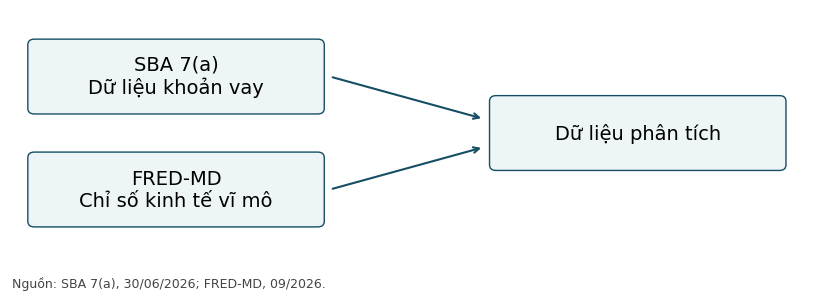

In [5]:

fig,ax=plt.subplots(figsize=(8.4,3));ax.set_xlim(0,10);ax.set_ylim(0,3.4);ax.axis('off')
boxes=[(.3,2,3.5,.9,'SBA 7(a)\nDữ liệu khoản vay'),
 (.3,.4,3.5,.9,'FRED-MD\nChỉ số kinh tế vĩ mô'),
 (6,1.2,3.5,.9,'Dữ liệu phân tích')]
for x,y,w,h,label in boxes:
 ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=.08',facecolor='#edf5f7',edgecolor=COLOR))
 ax.text(x+w/2,y+h/2,label,ha='center',va='center',fontsize=14)
for start,end in [((3.95,2.45),(5.85,1.85)),((3.95,.85),(5.85,1.45))]:
 ax.annotate('',xy=end,xytext=start,arrowprops={'arrowstyle':'->','color':COLOR,'lw':1.5})
fig.text(.02,.025,f'Nguồn: SBA 7(a), {SNAPSHOT_VI}; FRED-MD, 09/2026.',fontsize=9,color='#444444')
fig.tight_layout(rect=(0,.10,1,1))
fig.savefig(FIGURES/'S1_so_do_du_lieu.png',dpi=200,bbox_inches='tight')
plt.show();plt.close(fig)


## 5. H1, H2, H4, H5 và biểu đồ thiếu (2.2–2.3.2)
Tất cả thống kê tính trên dữ liệu đầy đủ. Boxplot ẩn điểm ngoài râu để dễ đọc nhưng không loại chúng khỏi phép tính.

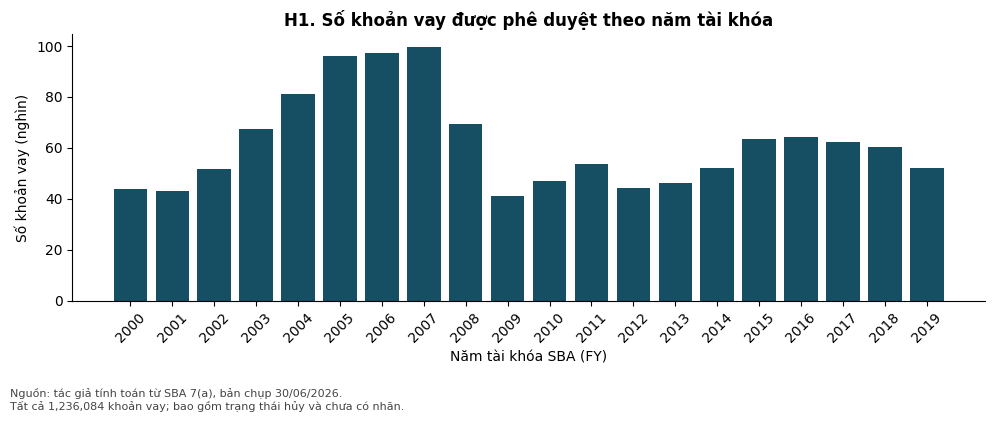

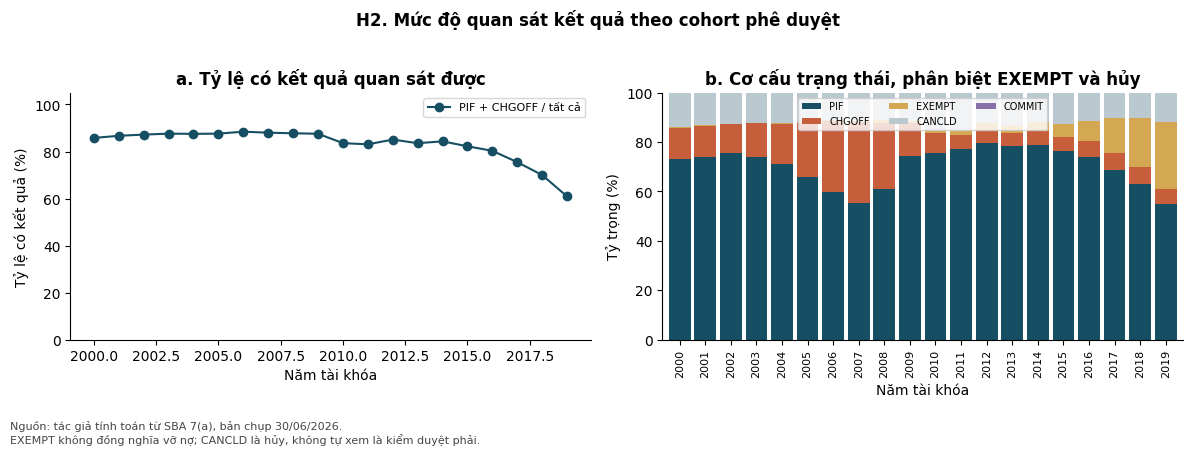

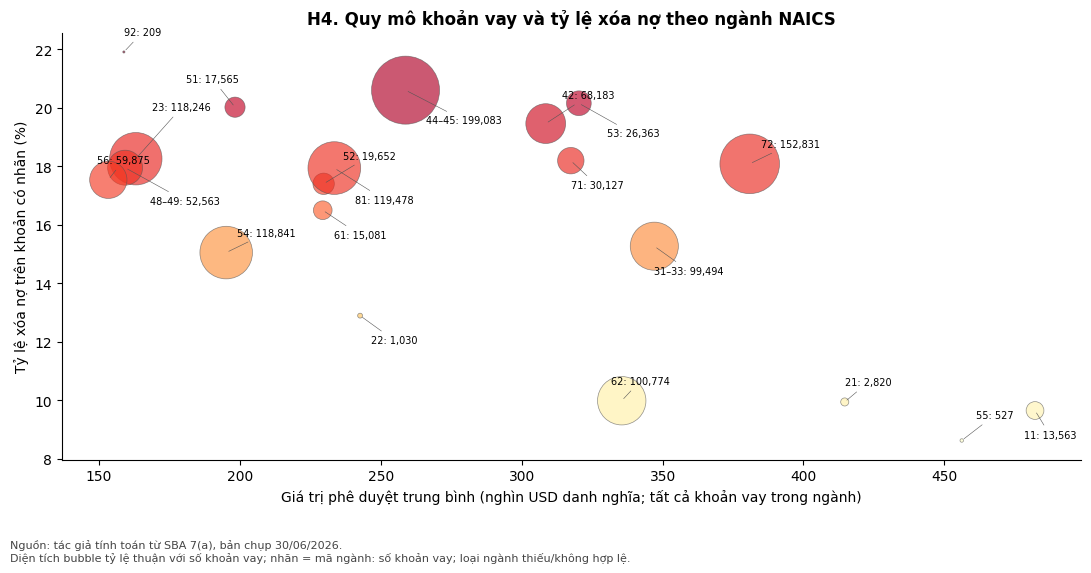

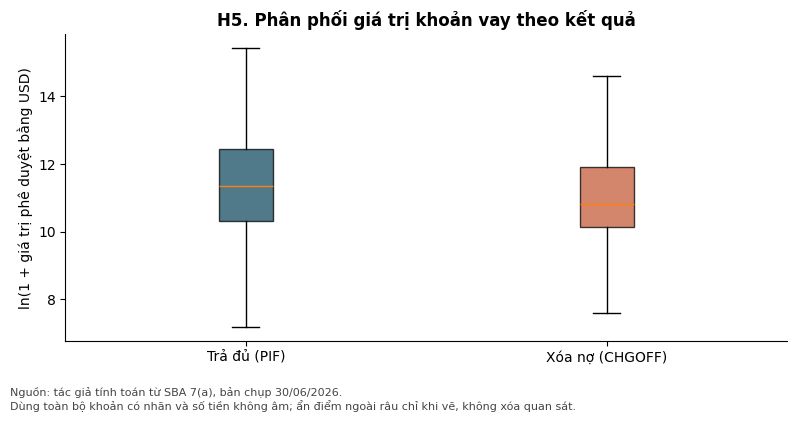

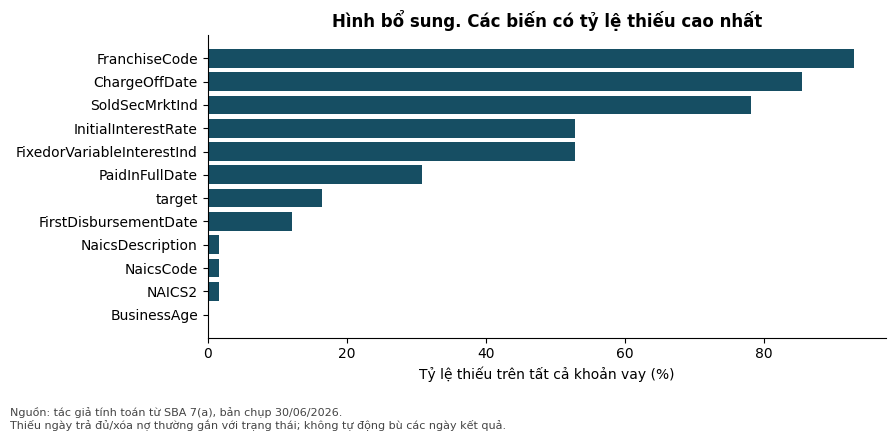

In [6]:

fig,ax=plt.subplots(figsize=(10,4.4))
ax.bar(cohort.index.astype(str),cohort.n_all/1000,color=COLOR)
ax.set(xlabel='Năm tài khóa SBA (FY)',ylabel='Số khoản vay (nghìn)',title='H1. Số khoản vay được phê duyệt theo năm tài khóa')
ax.tick_params(axis='x',rotation=45)
savefig(fig,'H1_so_khoan_vay_theo_fy',f'Tất cả {len(loans):,} khoản vay; bao gồm trạng thái hủy và chưa có nhãn.')
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].plot(cohort.index,cohort.resolved_rate*100,'o-',color=COLOR,label='PIF + CHGOFF / tất cả')
axes[0].set(xlabel='Năm tài khóa',ylabel='Tỷ lệ có kết quả (%)',ylim=(0,105),title='a. Tỷ lệ có kết quả quan sát được');axes[0].legend(fontsize=8)
status_order=[s for s in ['PIF','CHGOFF','EXEMPT','CANCLD','COMMIT'] if s in statuses]
shares=statuses[status_order].div(statuses.sum(axis=1),axis=0)*100
shares.plot.bar(stacked=True,ax=axes[1],color=['#164e63','#c65d3b','#d4a853','#bac8cf','#8a70a8'][:len(status_order)],width=.85)
axes[1].set(xlabel='Năm tài khóa',ylabel='Tỷ trọng (%)',title='b. Cơ cấu trạng thái, phân biệt EXEMPT và hủy')
axes[1].legend(fontsize=7,loc='upper center',ncol=3);axes[1].tick_params(axis='x',labelsize=8)
fig.suptitle('H2. Mức độ quan sát kết quả theo cohort phê duyệt',fontweight='bold')
savefig(fig,'H2_kiem_duyet_theo_fy','EXEMPT không đồng nghĩa vỡ nợ; CANCLD là hủy, không tự xem là kiểm duyệt phải.')

industry=rate_table('NAICS2').dropna(subset=['NAICS2','rate']).sort_values('NAICS2')
fig,ax=plt.subplots(figsize=(11,6))
size=industry.n_all/industry.n_all.max()*2400
ax.scatter(industry.mean_approval/1000,industry.rate*100,s=size,c=industry.rate,cmap='YlOrRd',alpha=.65,edgecolors='#555555',linewidths=.5)
# Mỗi bubble ghi mã ngành và số khoản vay, nhãn lệch luân phiên để hạn chế chồng lấn.
offsets={'23':(12,35),'48–49':(18,-26),'56':(-8,12),'51':(-35,18),'52':(14,18),
         '81':(15,-25),'55':(10,16),'44–45':(15,-24),'53':(20,-24),'42':(12,18)}
for i,row in enumerate(industry.itertuples()):
 ax.annotate(f'{row.NAICS2}: {row.n_all:,}',(row.mean_approval/1000,row.rate*100),
             xytext=offsets.get(row.NAICS2,((i%3-1)*8,12 if i%2 else -20)),textcoords='offset points',fontsize=7,
             arrowprops={'arrowstyle':'-','lw':.4,'color':'#555555'})
ax.set(xlabel='Giá trị phê duyệt trung bình (nghìn USD danh nghĩa; tất cả khoản vay trong ngành)',
 ylabel='Tỷ lệ xóa nợ trên khoản có nhãn (%)',title='H4. Quy mô khoản vay và tỷ lệ xóa nợ theo ngành NAICS')
savefig(fig,'H4_bubble_nganh','Diện tích bubble tỷ lệ thuận với số khoản vay; nhãn = mã ngành: số khoản vay; loại ngành thiếu/không hợp lệ.')

groups=[np.log1p(resolved.loc[resolved.target.eq(t)&resolved.GrossApproval.ge(0),'GrossApproval'].dropna()) for t in [0,1]]
fig,ax=plt.subplots(figsize=(8,4.4))
bp=ax.boxplot(groups,tick_labels=['Trả đủ (PIF)','Xóa nợ (CHGOFF)'],showfliers=False,patch_artist=True)
for patch,color in zip(bp['boxes'],[COLOR,ACCENT]):patch.set_facecolor(color);patch.set_alpha(.75)
ax.set(ylabel='ln(1 + giá trị phê duyệt bằng USD)',title='H5. Phân phối giá trị khoản vay theo kết quả')
savefig(fig,'H5_box_quy_mo_theo_nhan','Dùng toàn bộ khoản có nhãn và số tiền không âm; ẩn điểm ngoài râu chỉ khi vẽ, không xóa quan sát.')

miss_top=missing.loc[missing.missing_n.gt(0)].head(12).sort_values('missing_pct')
fig,ax=plt.subplots(figsize=(9,4.6));ax.barh(miss_top.variable,miss_top.missing_pct,color=COLOR)
ax.set(xlabel='Tỷ lệ thiếu trên tất cả khoản vay (%)',title='Hình bổ sung. Các biến có tỷ lệ thiếu cao nhất')
savefig(fig,'S2_thieu_du_lieu','Thiếu ngày trả đủ/xóa nợ thường gắn với trạng thái; không tự động bù các ngày kết quả.')


## 6. H3: bản đồ theo bang (2.3.2)
PNG dựng trực tiếp từ TopoJSON, không cần Chrome/Kaleido. Xuất thêm choropleth Plotly HTML để xem mẫu số và khoảng tin cậy. Lãnh thổ không có hình học được lưu ở bảng B12. Mã nhóm dưới 100 khoản có nhãn được đánh dấu low_n trong bảng, không tự loại.

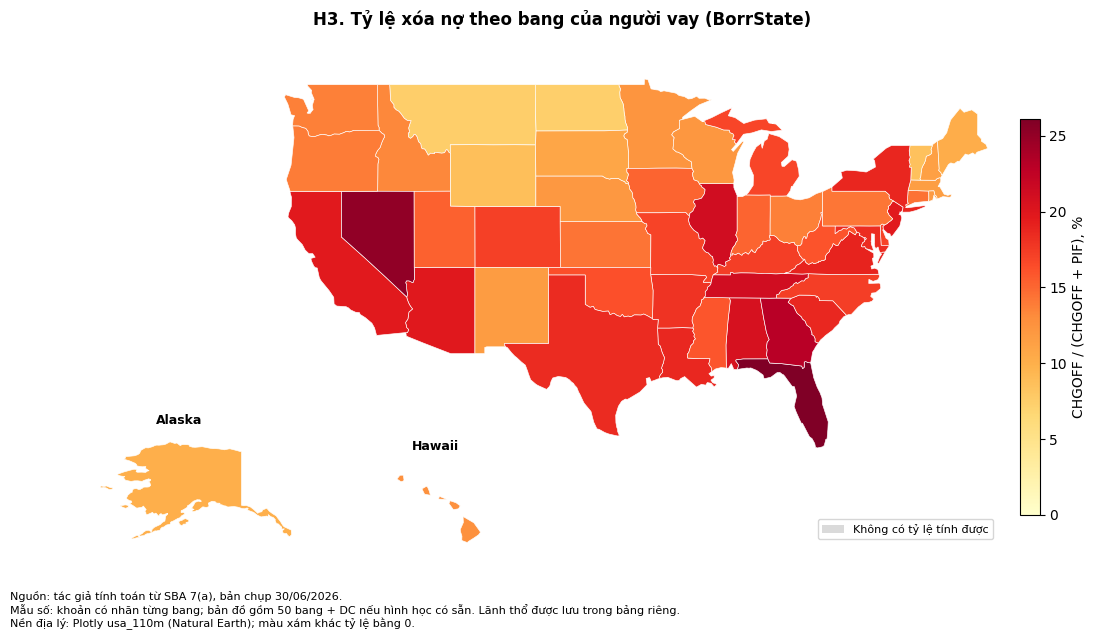

,BorrState,n_all,mean_approval,n_resolved,n_chgoff,rate,ci_low,ci_high,low_n
0,AE,2,32500.000000,2,0,0.000000,0.000000e+00,0.657620,True
4,AS,14,65928.571429,11,5,0.454545,2.127127e-01,0.719908,True
12,FM,4,102625.000000,4,0,0.000000,0.000000e+00,0.489891,True
14,GU,973,120828.507708,821,55,0.066991,5.182789e-02,0.086188,False
26,MH,4,232250.000000,3,0,0.000000,5.551115e-17,0.561497,True
30,MP,35,374500.000000,21,1,0.047619,8.455988e-03,0.226694,True
45,PR,12312,104652.878411,10173,1423,0.139880,1.332756e-01,0.146756,False
46,PW,8,32500.000000,6,1,0.166667,3.005337e-02,0.563503,True
54,VI,310,160097.838710,234,39,0.166667,1.243826e-01,0.219718,False


In [7]:

# Giải mã TopoJSON của Plotly thành GeoJSON; cùng dữ liệu dùng cho PNG và choropleth HTML.
topo=json.loads((META/'usa_110m.json').read_text(encoding='utf-8'))
scale=np.array(topo['transform']['scale']);translate=np.array(topo['transform']['translate'])
decoded=[np.cumsum(np.array(a,dtype=float),axis=0)*scale+translate for a in topo['arcs']]
def ring(ids):
    segments=[decoded[i] if i>=0 else decoded[~i][::-1] for i in ids]
    return np.concatenate([s if j==0 else s[1:] for j,s in enumerate(segments)]).tolist()
features=[]
for geom in topo['objects']['subunits']['geometries']:
    if geom.get('properties',{}).get('gu')!='USA':continue
    coords=([ring(r) for r in geom['arcs']] if geom['type']=='Polygon' else
            [[ring(r) for r in poly] for poly in geom['arcs']])
    features.append({'type':'Feature','id':geom['id'],'properties':{'state':geom['id']},
                     'geometry':{'type':geom['type'],'coordinates':coords}})
geojson={'type':'FeatureCollection','features':features}
save_json(geojson,META/'usa_states.geojson')
state=rate_table('BorrState');state=state.dropna(subset=['BorrState'])
rates=state.set_index('BorrState').rate
norm=Normalize(vmin=0,vmax=float(rates.reindex([f['id'] for f in features]).max()*100));cmap=plt.get_cmap('YlOrRd')
fig=plt.figure(figsize=(11.5,6.6));ax=fig.add_axes([.04,.27,.88,.60]);ak=fig.add_axes([.06,.12,.22,.20]);hi=fig.add_axes([.30,.12,.16,.16])
for f in features:
    code=f['id'];a=ak if code=='AK' else hi if code=='HI' else ax
    v=rates.get(code,np.nan);color='#dadada' if pd.isna(v) else cmap(norm(v*100))
    polys=f['geometry']['coordinates']
    if f['geometry']['type']=='Polygon':polys=[polys]
    for poly in polys:
        outer=np.array(poly[0])
        if code=='AK':outer[:,0]=np.where(outer[:,0]>0,outer[:,0]-360,outer[:,0])
        a.add_patch(Polygon(outer,facecolor=color,edgecolor='white',lw=.45))
for a,limits in [(ax,(-125,-66,24,50)),(ak,(-180,-129,50,73)),(hi,(-161,-154,18,23))]:
 a.set_xlim(limits[:2]);a.set_ylim(limits[2:]);a.set_aspect(1.25);a.axis('off')
ak.set_title('Alaska',fontsize=9);hi.set_title('Hawaii',fontsize=9)
cb=fig.colorbar(ScalarMappable(norm=norm,cmap=cmap),ax=[ax,ak,hi],fraction=.025,pad=.02,shrink=.8)
cb.set_label('CHGOFF / (CHGOFF + PIF), %')
fig.legend(handles=[Patch(facecolor='#dadada',label='Không có tỷ lệ tính được')],loc='lower right',bbox_to_anchor=(.88,.15),fontsize=8)
fig.suptitle('H3. Tỷ lệ xóa nợ theo bang của người vay (BorrState)',fontweight='bold',y=.96)
fig.text(.02,.025,SOURCE+'\nMẫu số: khoản có nhãn từng bang; bản đồ gồm 50 bang + DC nếu hình học có sẵn. Lãnh thổ được lưu trong bảng riêng.\nNền địa lý: Plotly usa_110m (Natural Earth); màu xám khác tỷ lệ bằng 0.',fontsize=8)
fig.savefig(FIGURES/'H3_ban_do_bang.png',dpi=200,bbox_inches='tight');plt.show();plt.close(fig)
import plotly.express as px
mapdata=state[state.BorrState.isin([f['id'] for f in features])].copy();mapdata['rate_pct']=mapdata.rate*100
interactive=px.choropleth(mapdata,geojson=geojson,locations='BorrState',featureidkey='id',color='rate_pct',
 hover_data=['n_all','n_resolved','n_chgoff','ci_low','ci_high','low_n'],scope='usa',color_continuous_scale='YlOrRd',
 labels={'rate_pct':'Xóa nợ (%)','BorrState':'Bang'},title='H3. Tỷ lệ xóa nợ theo bang; mẫu số = CHGOFF + PIF')
interactive.update_geos(fitbounds='locations',visible=False)
interactive.write_html(FIGURES/'H3_ban_do_bang.html',include_plotlyjs=True)
table(state.loc[~state.BorrState.isin([f['id'] for f in features])],'B12_dia_ly_ngoai_ban_do')


## 7. H6: Pearson, Spearman và Cramér’s V (2.3.3)
Pearson dùng thang gốc; Spearman dùng thứ hạng. Thiếu loại theo từng cặp, xuất ma trận số quan sát tương ứng. Không dùng mã số ngành như biến liên tục. Cramér’s V = sqrt(chi2 / [n × min(r−1,k−1)]), không hiệu chỉnh Yates và không diễn giải p-value.

,variable,GrossApproval,SBAGuaranteedApproval,TermInMonths,JobsSupported,InitialInterestRate
0,GrossApproval,1.000000,0.995061,0.515023,0.198614,-0.241156
1,SBAGuaranteedApproval,0.995061,1.000000,0.514679,0.195494,-0.238438
2,TermInMonths,0.515023,0.514679,1.000000,0.054332,-0.210265
3,JobsSupported,0.198614,0.195494,0.054332,1.000000,-0.142328
4,InitialInterestRate,-0.241156,-0.238438,-0.210265,-0.142328,1.000000


,variable,GrossApproval,SBAGuaranteedApproval,TermInMonths,JobsSupported,InitialInterestRate
0,GrossApproval,1.000000,0.991442,0.542602,0.295981,-0.425026
1,SBAGuaranteedApproval,0.991442,1.000000,0.558023,0.275774,-0.420260
2,TermInMonths,0.542602,0.558023,1.000000,0.103327,-0.134116
3,JobsSupported,0.295981,0.275774,0.103327,1.000000,-0.192178
4,InitialInterestRate,-0.425026,-0.420260,-0.134116,-0.192178,1.000000


,variable,GrossApproval,SBAGuaranteedApproval,TermInMonths,JobsSupported,InitialInterestRate
0,GrossApproval,1236084,1236084,1236084,1236082,582384
1,SBAGuaranteedApproval,1236084,1236084,1236084,1236082,582384
2,TermInMonths,1236084,1236084,1236084,1236082,582384
3,JobsSupported,1236082,1236082,1236082,1236082,582382
4,InitialInterestRate,582384,582384,582384,582382,582384


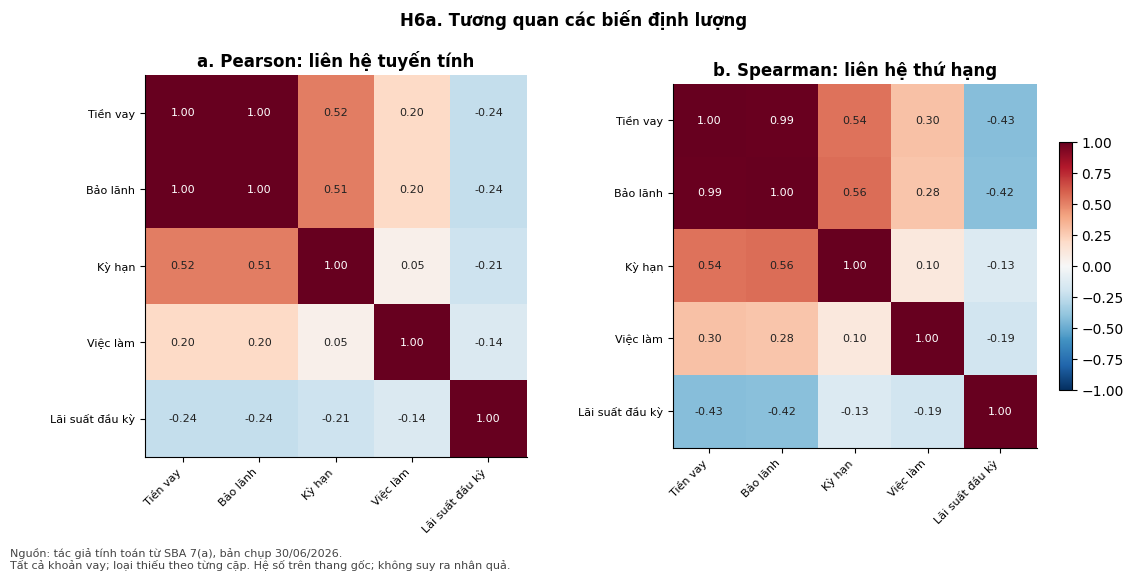

,variable,BusinessType,ProcessingMethod,NAICS2,BorrState,LoanStatus
0,BusinessType,1.000000,0.133055,0.111011,0.160359,0.054508
1,ProcessingMethod,0.133055,1.000000,0.077328,0.115382,0.124171
2,NAICS2,0.111011,0.077328,1.000000,0.082013,0.044866
3,BorrState,0.160359,0.115382,0.082013,1.000000,0.057015
4,LoanStatus,0.054508,0.124171,0.044866,0.057015,1.000000


,variable,BusinessType,ProcessingMethod,NAICS2,BorrState,LoanStatus
0,BusinessType,1235534.0,1235534.0,1215831.0,1235534.0,1235534.0
1,ProcessingMethod,1235534.0,1236084.0,1216305.0,1236084.0,1236084.0
2,NAICS2,1215831.0,1216305.0,1216305.0,1216305.0,1216305.0
3,BorrState,1235534.0,1236084.0,1216305.0,1236084.0,1236084.0
4,LoanStatus,1235534.0,1236084.0,1216305.0,1236084.0,1236084.0


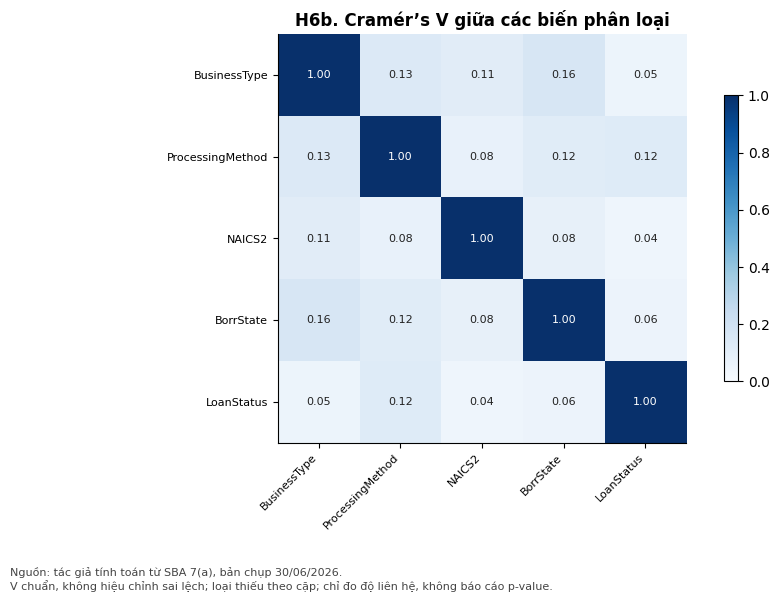

**Giới hạn:** Wilson là khoảng mô tả dựa trên giả định nhị thức độc lập, chưa điều chỉnh cụm tháng/ngân hàng. Cramér’s V có thể tăng theo số nhóm. EDA không quyết định ngưỡng mô hình, chia test hoặc giả thuyết nhân quả.

In [8]:

# Biến kết quả và cohort không nằm trong ma trận đặc trưng định lượng.
num=['GrossApproval','SBAGuaranteedApproval','TermInMonths','JobsSupported','InitialInterestRate']
labels=['Tiền vay','Bảo lãnh','Kỳ hạn','Việc làm','Lãi suất đầu kỳ']
pearson=loans[num].corr(method='pearson');spearman=loans[num].corr(method='spearman')
table(pearson.reset_index(names='variable'),'B13_pearson')
table(spearman.reset_index(names='variable'),'B14_spearman')
pairn=pd.DataFrame({c:loans[c].notna().astype('int64') for c in num})
pairn=pairn.T.dot(pairn)
table(pairn.reset_index(names='variable'),'B15_n_cap_bien_so')
def heat(ax,frame,names,title,vmin=-1,vmax=1):
    a=frame.to_numpy(dtype=float);im=ax.imshow(a,cmap='RdBu_r' if vmin<0 else 'Blues',vmin=vmin,vmax=vmax)
    ax.set_xticks(range(len(names)),names,rotation=45,ha='right',fontsize=8)
    ax.set_yticks(range(len(names)),names,fontsize=8);ax.set_title(title)
    for i in range(len(names)):
        for j in range(len(names)):
            if np.isfinite(a[i,j]):ax.text(j,i,f'{a[i,j]:.2f}',ha='center',va='center',fontsize=8,color='white' if abs(a[i,j])>.65 else '#222222')
    return im
fig,axes=plt.subplots(1,2,figsize=(11.5,5.8))
heat(axes[0],pearson,labels,'a. Pearson: liên hệ tuyến tính');im=heat(axes[1],spearman,labels,'b. Spearman: liên hệ thứ hạng')
fig.colorbar(im,ax=axes[1],shrink=.65);fig.suptitle('H6a. Tương quan các biến định lượng',fontweight='bold')
savefig(fig,'H6a_tuong_quan_so','Tất cả khoản vay; loại thiếu theo từng cặp. Hệ số trên thang gốc; không suy ra nhân quả.')
cat=[c for c in ['BusinessType','ProcessingMethod','Subprogram','NAICS2','BorrState','LoanStatus'] if c in loans.columns]
V=pd.DataFrame(np.nan,index=cat,columns=cat);N=V.copy()
for a,b in itertools.combinations_with_replacement(cat,2):
    sub=loans[[a]].dropna() if a==b else loans[[a,b]].dropna()
    if a==b: value=1.0 if sub[a].nunique()>1 else np.nan
    else:
        contingency=pd.crosstab(sub[a],sub[b]);r,k=contingency.shape
        value=np.sqrt(chi2_contingency(contingency,correction=False)[0]/(len(sub)*min(r-1,k-1))) if min(r,k)>1 else np.nan
    V.loc[a,b]=V.loc[b,a]=value;N.loc[a,b]=N.loc[b,a]=len(sub)
table(V.reset_index(names='variable'),'B16_cramers_v')
table(N.reset_index(names='variable'),'B17_n_cap_bien_loai')
fig,ax=plt.subplots(figsize=(8.5,6.3));im=heat(ax,V,cat,"H6b. Cramér’s V giữa các biến phân loại",0,1)
fig.colorbar(im,ax=ax,shrink=.7)
savefig(fig,'H6b_cramers_v','V chuẩn, không hiệu chỉnh sai lệch; loại thiếu theo cặp; chỉ đo độ liên hệ, không báo cáo p-value.')
links=[]
for a,b in itertools.combinations(num,2):
 links.append({'a':a,'b':b,'pearson':float(pearson.loc[a,b]),'spearman':float(spearman.loc[a,b]),'n_pair':int(pairn.loc[a,b])})
save_json({'numeric_pairs':links,'cramers_v_with_status':V['LoanStatus'].drop('LoanStatus').to_dict()},META/'correlation_summary.json')
display(Markdown('**Giới hạn:** Wilson là khoảng mô tả dựa trên giả định nhị thức độc lập, chưa điều chỉnh cụm tháng/ngân hàng. Cramér’s V có thể tăng theo số nhóm. EDA không quyết định ngưỡng mô hình, chia test hoặc giả thuyết nhân quả.'))


## 8. Kiểm tra đầu ra
Việc chạy cục bộ không được coi là đã chạy Colab. Xem README và notebook_validation.json.

In [9]:

required_figures=['S1_so_do_du_lieu','H1_so_khoan_vay_theo_fy','H2_kiem_duyet_theo_fy','H3_ban_do_bang',
 'H4_bubble_nganh','H5_box_quy_mo_theo_nhan','H6a_tuong_quan_so','H6b_cramers_v']
assert all((FIGURES/(name+'.png')).exists() for name in required_figures)
assert cohort.n_all.sum()==len(loans)
assert cohort.n_resolved.sum()==len(resolved)
assert cohort.n_chgoff.sum()==resolved.target.sum()
assert np.allclose(pearson.to_numpy(),pearson.to_numpy().T,equal_nan=True)
assert np.allclose(V.to_numpy(),V.to_numpy().T,equal_nan=True)
assert V.stack().between(0,1+1e-12).all()
assert len(joined_keys)==len(loans)
save_json({'local_execution':'passed','colab_execution':'not_verified_in_Colab',
 'snapshot':DATASET['snapshot'],'source_hashes':audit['source_hashes'],
 'figures':required_figures,'loan_rows':len(loans),'resolved_rows':len(resolved),
 'no_borrower_identifiers':True,'macro_merge_preserves_rows':True},META/'notebook_validation.json')
print('Hoàn tất EDA:',len(loans),'khoản vay;',len(resolved),'có nhãn;',len(required_figures),'hình chính.')
def fmt(x,d=0):return f'{x:,.{d}f}'.replace(',','_').replace('.',',').replace('_','.')
display(Markdown(f"""### Diễn giải kết quả thực nghiệm

**Cấu trúc mẫu.** Bộ dữ liệu có {fmt(len(loans))} khoản vay; {fmt(len(resolved))} khoản đã trả đủ hoặc xóa nợ. Tỷ lệ xóa nợ trong tập này là {fmt(resolved.target.mean()*100,2)}%. Đây là tỷ lệ trên kết quả đã quan sát, không phải xác suất vỡ nợ vòng đời của mọi khoản đã được phê duyệt.

**Cohort và dữ liệu thiếu.** Tỷ lệ có kết quả giảm từ {fmt(cohort.loc[2000,'resolved_rate']*100,2)}% ở FY2000 xuống {fmt(cohort.loc[2019,'resolved_rate']*100,2)}% ở FY2019. Cần đọc cùng tỷ trọng EXEMPT và CANCLD; không thể gán toàn bộ phần chưa có nhãn cho kiểm duyệt phải. InitialInterestRate thiếu hoàn toàn ở FY2000–FY2008, nên các tương quan có lãi suất đại diện cho cửa sổ thời gian hẹp hơn.

**Phân phối.** Giá trị phê duyệt trung bình {fmt(loans.GrossApproval.mean(),2)} USD vượt trung vị {fmt(loans.GrossApproval.median())} USD, phù hợp với phân phối lệch phải. IQR chỉ là quy tắc đánh dấu; số tiền lớn không tự chứng minh sai dữ liệu. JobsSupported là ước lượng tự báo cáo trên hồ sơ; không thể suy ra số việc làm thực tế được tạo ra.

**Liên hệ.** GrossApproval–SBAGuaranteedApproval có Pearson {fmt(pearson.loc['GrossApproval','SBAGuaranteedApproval'],3)}, chủ yếu phù hợp với quan hệ cấu trúc giữa khoản vay và phần bảo lãnh. GrossApproval–JobsSupported có Pearson {fmt(pearson.loc['GrossApproval','JobsSupported'],3)} và Spearman {fmt(spearman.loc['GrossApproval','JobsSupported'],3)}. Chênh lệch hai thước đo cho thấy cần đọc cả thang gốc và thứ hạng, không tự chứng minh nguyên nhân. Cramér’s V với LoanStatus dùng năm trạng thái, không phải riêng nhãn nhị phân.

**Bàn giao.** Các bảng B1–B17 trong tables/ là nguồn để viết Chương 2. Đọc đầy đủ phần giới hạn và tài liệu tham khảo trong report/Chuong_2.md. Việc chọn mô hình và kiểm định thuộc các chương sau.
"""))


Hoàn tất EDA: 1236084 khoản vay; 1033447 có nhãn; 8 hình chính.


### Diễn giải kết quả thực nghiệm

**Cấu trúc mẫu.** Bộ dữ liệu có 1.236.084 khoản vay; 1.033.447 khoản đã trả đủ hoặc xóa nợ. Tỷ lệ xóa nợ trong tập này là 17,27%. Đây là tỷ lệ trên kết quả đã quan sát, không phải xác suất vỡ nợ vòng đời của mọi khoản đã được phê duyệt.

**Cohort và dữ liệu thiếu.** Tỷ lệ có kết quả giảm từ 85,78% ở FY2000 xuống 60,89% ở FY2019. Cần đọc cùng tỷ trọng EXEMPT và CANCLD; không thể gán toàn bộ phần chưa có nhãn cho kiểm duyệt phải. InitialInterestRate thiếu hoàn toàn ở FY2000–FY2008, nên các tương quan có lãi suất đại diện cho cửa sổ thời gian hẹp hơn.

**Phân phối.** Giá trị phê duyệt trung bình 266.432,11 USD vượt trung vị 89.500 USD, phù hợp với phân phối lệch phải. IQR chỉ là quy tắc đánh dấu; số tiền lớn không tự chứng minh sai dữ liệu. JobsSupported là ước lượng tự báo cáo trên hồ sơ; không thể suy ra số việc làm thực tế được tạo ra.

**Liên hệ.** GrossApproval–SBAGuaranteedApproval có Pearson 0,995, chủ yếu phù hợp với quan hệ cấu trúc giữa khoản vay và phần bảo lãnh. GrossApproval–JobsSupported có Pearson 0,199 và Spearman 0,296. Chênh lệch hai thước đo cho thấy cần đọc cả thang gốc và thứ hạng, không tự chứng minh nguyên nhân. Cramér’s V với LoanStatus dùng năm trạng thái, không phải riêng nhãn nhị phân.

**Bàn giao.** Các bảng B1–B17 trong tables/ là nguồn để viết Chương 2. Đọc đầy đủ phần giới hạn và tài liệu tham khảo trong report/Chuong_2.md. Việc chọn mô hình và kiểm định thuộc các chương sau.
